# Núcleo 4 — Peso de la coparticipación en las cuentas de Córdoba

Acá calculo qué porcentaje de los ingresos de Córdoba viene de la coparticipación
federal, cómo se movieron en términos reales la recaudación propia y la coparticipación,
y uso el simulador del Núcleo 3 para traducir un shock de recaudación nacional en un
impacto sobre el ingreso provincial total.

Fuente: `data/raw/ingresos_cordoba/serie_recaudacion_provincial.xlsx`, la recaudación
administrada por la Dirección General de Rentas de Córdoba. Uso estas filas del mismo
archivo:

- **Total** (código 1): recursos de origen provincial + recursos de origen nacional. Es
  mi proxy de "ingresos corrientes totales". Excluye lo recaudado por otros organismos
  provinciales, como EPEC, según la nota al pie del archivo, así que no es el ingreso
  corriente total del sector público provincial en sentido estricto.
- **Recursos de origen provincial** (1.1): la recaudación propia (Ingresos Brutos,
  Inmobiliario, Automotor, Sellos, etc.).
- **Coparticipación federal**: la suma de tres filas, con la misma definición que el
  Núcleo 1. Son la coparticipación Ley 23.548 con la compensación y el bono del Consenso
  Fiscal (1.2.1), el Fondo para Obras de Infraestructura y Programas Sociales (1.2.3) y el
  Financiamiento Educativo de la Ley 26.075 (1.2.5.1). Las dos últimas son partes de la
  coparticipación que la provincia registra en filas aparte: la 1.2.3 era la asignación
  específica de Ganancias que desde 2018 Nación transfiere por la Ley 23.548, y la
  1.2.5.1 es la parte que la Ley 26.075 afecta a educación.

Numerador y denominador salen del mismo archivo. En la sección 3 comparo esa
coparticipación con la que informa Nación (Núcleo 1).

El rango es 2015-2025: el archivo empieza en enero de 2015 y 2026 está incompleto. Los
montos en pesos constantes usan el mismo IPC (base 2016) que el Núcleo 1. El archivo
dice estar en "millones de pesos" pero está en pesos; el detalle está en
`docs/methodology.md`.

Trabajo sobre `data/processed/dependencia_fiscal_cordoba.csv`, generado por
`scripts/build_dependencia_fiscal.py`.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

BASE_DIR = Path("..").resolve() if Path("../data").exists() else Path(".").resolve()
sys.path.insert(0, str(BASE_DIR / "scripts"))

from build_dependencia_fiscal import build_ratio, calcular_sensibilidad

COLOR_RATIO = "#2a78d6"
COLOR_NEGATIVO = "#e34948"
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "text.color": INK_PRIMARY,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
})

FIGURES_DIR = BASE_DIR / "output" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = build_ratio()
df


AVISO: años con menos de 12 meses de datos (se descartan, no se completan con supuestos): [2026]
AVISO: el año 2016 tiene solo 1 mes(es) de IPC oficial; su promedio se estima en load_ipc_empalmado().


,anio,ingresos_totales_pesos,recursos_propios_pesos,coparticipacion_pesos,compensacion_consenso_fiscal_pesos,ratio_coparticipacion_ingresos,participacion_recursos_propios,ingresos_totales_real_base2016_pesos,recursos_propios_real_base2016_pesos,coparticipacion_real_base2016_pesos,coparticipacion_ron_pesos,diferencia_ron_vs_provincia
0,2015,6.578461e+10,2.756254e+10,3.423099e+10,0.000000e+00,0.520350,0.418982,8.930659e+10,3.741781e+10,4.647064e+10,3.422249e+10,-0.000248
1,2016,9.201533e+10,3.846950e+10,4.862071e+10,0.000000e+00,0.528398,0.418077,9.201533e+10,3.846950e+10,4.862071e+10,4.862852e+10,0.000161
2,2017,1.221641e+11,5.225699e+10,6.387882e+10,0.000000e+00,0.522894,0.427761,9.863482e+10,4.219210e+10,5.157552e+10,6.393253e+10,0.000841
3,2018,1.640963e+11,6.873978e+10,8.919304e+10,1.706643e+09,0.543541,0.418899,9.866955e+10,4.133258e+10,5.363093e+10,8.866155e+10,-0.005959
4,2019,2.270608e+11,9.203987e+10,1.284442e+11,3.130179e+09,0.565682,0.405353,8.891633e+10,3.604253e+10,5.029836e+10,1.267340e+11,-0.013315
5,2020,3.062720e+11,1.222806e+11,1.665154e+11,3.523318e+09,0.543685,0.399255,8.445241e+10,3.371804e+10,4.591549e+10,1.650811e+11,-0.008613
6,2021,5.031439e+11,2.042445e+11,2.734183e+11,4.496307e+09,0.543420,0.405937,9.348365e+10,3.794844e+10,5.080085e+10,2.721436e+11,-0.004662
7,2022,8.982800e+11,3.484412e+11,5.126426e+11,6.370240e+09,0.570694,0.387898,9.679222e+10,3.754553e+10,5.523870e+10,5.114214e+11,-0.002382
8,2023,1.965302e+12,7.535377e+11,1.132228e+12,1.201071e+10,0.576109,0.383421,9.069675e+10,3.477502e+10,5.225119e+10,1.131147e+12,-0.000955
9,2024,5.945371e+12,2.381433e+12,3.345436e+12,2.667626e+10,0.562696,0.400552,8.577252e+10,3.435639e+10,4.826384e+10,3.345634e+12,0.000059


## 1. Evolución del ratio coparticipación / ingresos totales (2015-2025)

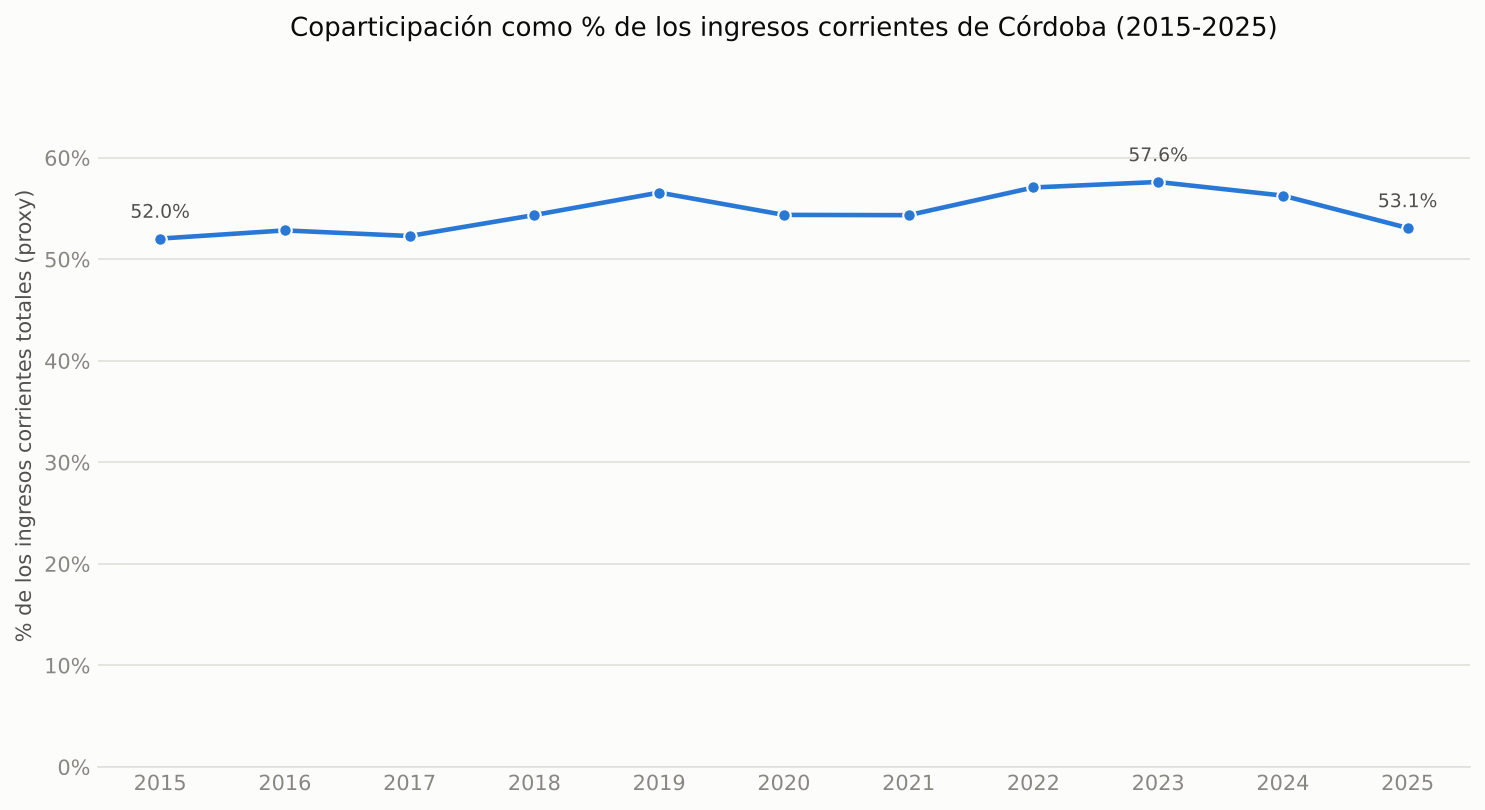

In [2]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)
ax.plot(
    df["anio"], df["ratio_coparticipacion_ingresos"] * 100,
    color=COLOR_RATIO, linewidth=2.2, marker="o", markersize=6,
    markerfacecolor=COLOR_RATIO, markeredgecolor=SURFACE, markeredgewidth=1,
)

idx_max = df["ratio_coparticipacion_ingresos"].idxmax()
for idx in sorted(set([df.index[0], idx_max, df.index[-1]])):
    row = df.loc[idx]
    ax.annotate(
        f"{row['ratio_coparticipacion_ingresos']:.1%}",
        (row["anio"], row["ratio_coparticipacion_ingresos"] * 100),
        textcoords="offset points", xytext=(0, 10), ha="center",
        fontsize=9, color=INK_SECONDARY,
    )

ax.set_title("Coparticipación como % de los ingresos corrientes de Córdoba (2015-2025)", fontsize=12.5, color=INK_PRIMARY, pad=14)
ax.set_ylabel("% de los ingresos corrientes totales (proxy)", fontsize=10)
ax.set_xlabel("")
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))
ax.set_ylim(0, max(df["ratio_coparticipacion_ingresos"] * 100) * 1.2)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "dependencia_fiscal_cordoba.png", dpi=300, facecolor=SURFACE)
plt.show()


La coparticipación pasó de representar el 52,0% de los ingresos de Córdoba en 2015 a un
máximo de 57,6% en 2023, y bajó a 53,1% en 2025. La tendencia de la década es de mayor
dependencia, con una reversión marcada en el último año.

## 2. Recaudación propia y coparticipación en pesos constantes (base 2016)

El ratio da igual en pesos nominales o reales, porque el deflactor se cancela. Para saber
por qué se movió hay que mirar cada serie por separado en poder de compra constante.

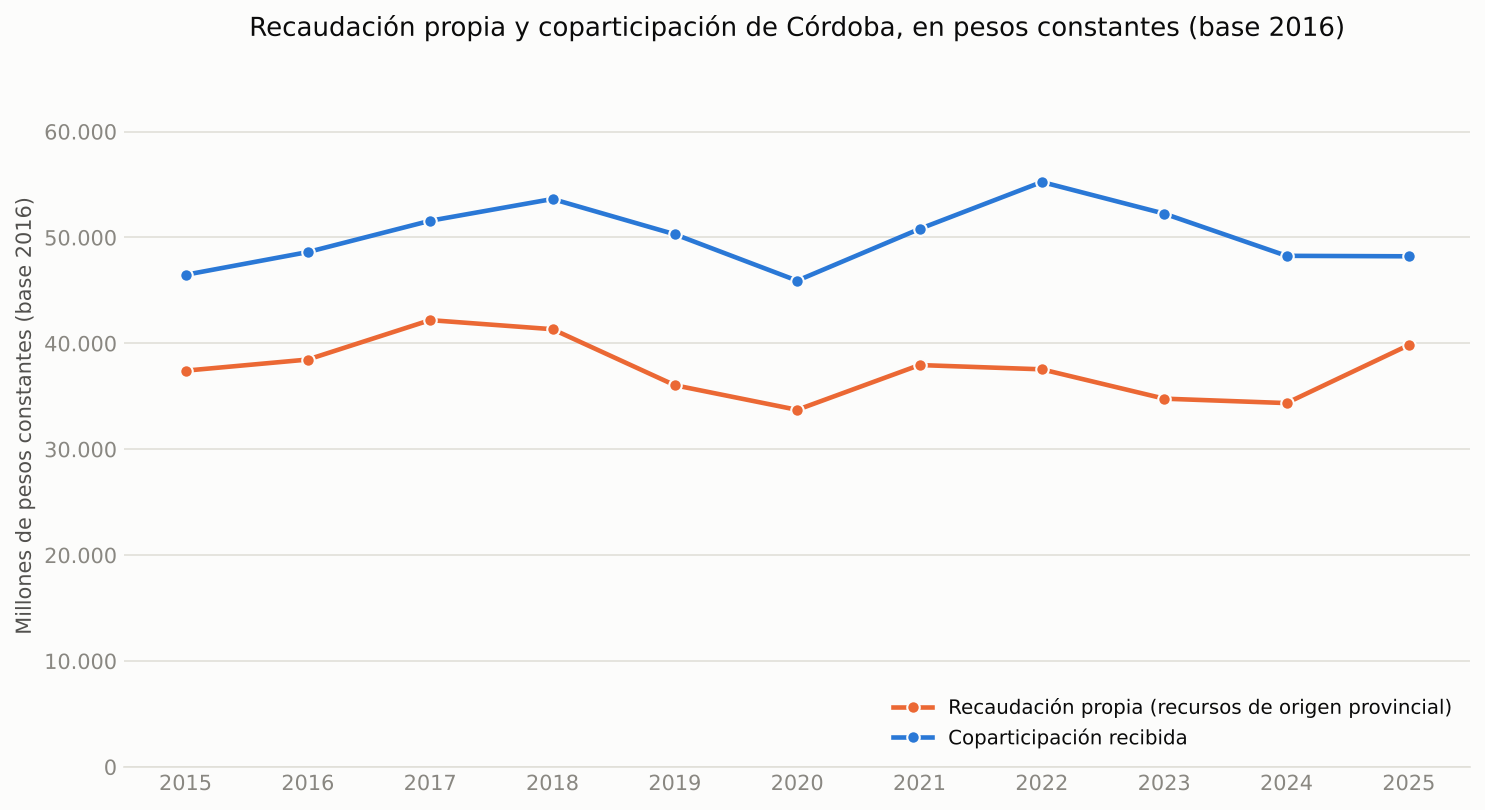

In [3]:
COLOR_INGRESOS = "#eb6834"

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

ax.plot(
    df["anio"], df["recursos_propios_real_base2016_pesos"] / 1e6,
    color=COLOR_INGRESOS, linewidth=2.2, marker="o", markersize=6,
    markerfacecolor=COLOR_INGRESOS, markeredgecolor=SURFACE, markeredgewidth=1,
    label="Recaudación propia (recursos de origen provincial)",
)
ax.plot(
    df["anio"], df["coparticipacion_real_base2016_pesos"] / 1e6,
    color=COLOR_RATIO, linewidth=2.2, marker="o", markersize=6,
    markerfacecolor=COLOR_RATIO, markeredgecolor=SURFACE, markeredgewidth=1,
    label="Coparticipación recibida",
)

ax.set_title(
    "Recaudación propia y coparticipación de Córdoba, en pesos constantes (base 2016)",
    fontsize=12.5, color=INK_PRIMARY, pad=14,
)
ax.set_ylabel("Millones de pesos constantes (base 2016)", fontsize=10)
ax.set_xlabel("")
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.set_ylim(0, df[["recursos_propios_real_base2016_pesos", "coparticipacion_real_base2016_pesos"]].max().max() / 1e6 * 1.2)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color(GRID_COLOR)
ax.tick_params(axis="both", length=0)
ax.legend(frameon=False, loc="lower right", fontsize=9.5)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "dependencia_fiscal_cordoba_real.png", dpi=300, facecolor=SURFACE)
plt.show()


Entre 2015 y 2025, en pesos constantes de 2016, la coparticipación que recibe Córdoba
creció un 3,8% (de \$46.471 a \$48.219 millones, con un máximo de \$55.239 millones en
2022) y la recaudación propia, un 6,5% (de \$37.418 a \$39.837 millones). Pero el
resultado de punta a punta esconde lo importante: la recaudación propia tocó su máximo
en 2017 (\$42.192 millones), cayó un 20% hasta 2020 y se mantuvo cerca de ese piso
hasta 2024. La coparticipación también cayó entre 2017 y 2020 (−11%), pero se recuperó
un 20% hasta 2022.

Eso explica el ratio de la sección anterior. La dependencia subió hasta 2023 porque la
recaudación propia no se recuperó de la caída de 2017-2020 y la coparticipación sí. En
2025 pasó lo inverso: la recaudación propia se recuperó (+16,0% real contra 2024, aunque
todavía 5,6% por debajo de 2017), la coparticipación quedó igual (−0,1%) y el ratio bajó
a 53,1%.

## 3. Control: la coparticipación según Nación y según Córdoba

La serie de transferencias de Hacienda (RON, la que uso en el Núcleo 1) y el archivo de
Rentas de Córdoba deberían registrar la misma coparticipación. Lo comparo año por año:

In [4]:
control = df[["anio", "coparticipacion_pesos", "coparticipacion_ron_pesos", "diferencia_ron_vs_provincia"]].copy()
control["coparticipacion_pesos"] = control["coparticipacion_pesos"] / 1e6
control["coparticipacion_ron_pesos"] = control["coparticipacion_ron_pesos"] / 1e6
control["diferencia_ron_vs_provincia"] = control["diferencia_ron_vs_provincia"].map(lambda x: f"{x:+.1%}")
control.columns = ["Año", "Según Córdoba (millones $)", "Según Nación, RON (millones $)", "Diferencia"]
control.style.format({"Según Córdoba (millones $)": "{:,.0f}", "Según Nación, RON (millones $)": "{:,.0f}"}).hide(axis="index")

Año,Según Córdoba (millones $),"Según Nación, RON (millones $)",Diferencia
2015,"34,231","34,222",-0.0%
2016,"48,621","48,629",+0.0%
2017,"63,879","63,933",+0.1%
2018,"89,193","88,662",-0.6%
2019,"128,444","126,734",-1.3%
2020,"166,515","165,081",-0.9%
2021,"273,418","272,144",-0.5%
2022,"512,643","511,421",-0.2%
2023,"1,132,228","1,131,147",-0.1%
2024,"3,345,436","3,345,634",+0.0%


Las dos fuentes son independientes y coinciden todos los años, con diferencias menores
al 1,6% (y al 0,1% desde 2023). Eso confirma dos cosas: que el archivo provincial está en
pesos y no en millones, y que las dos definiciones de coparticipación son la misma.

No fue así desde el principio. Mientras usé solo la fila 1.2.1, la serie nacional
registraba entre 14% y 17% más que la provincial desde 2018. La causa estaba en el
Consenso Fiscal: ese año eliminó la asignación específica de Ganancias y pasó esa plata a
la Ley 23.548. Hacienda la suma a la coparticipación, mientras Córdoba la sigue
anotando en la fila 1.2.3. Con esa fila incluida, la diferencia desaparece, y la serie
del Núcleo 1 suma esa asignación también antes de 2018 para no tener un quiebre.

## 4. Indicador de sensibilidad: shock de recaudación nacional → impacto en el ingreso provincial

Uso el simulador del Núcleo 3 (`scripts/simulator.py`) para traducir una caída
porcentual de la recaudación nacional coparticipable en un impacto en pesos sobre la
coparticipación de Córdoba, y lo expreso como % de sus ingresos totales de 2025. La masa
coparticipable de referencia la calibro para que el coeficiente de Córdoba reproduzca la
coparticipación que registra el archivo provincial en 2025, sin la compensación del
Consenso Fiscal (un monto fijo que no se mueve con la recaudación); así el impacto y el
denominador salen de la misma fuente.

In [5]:
sensibilidad = calcular_sensibilidad(anio_referencia=2025, escenarios=[-0.05, -0.10])
tabla = sensibilidad.copy()
tabla["variacion_pct_recaudacion"] = tabla["variacion_pct_recaudacion"].map(lambda x: f"{x:.0%}")
tabla["impacto_copart_cordoba_pesos"] = tabla["impacto_copart_cordoba_pesos"].map(lambda x: f"${x/1e9:,.1f} mil M")
tabla["impacto_pct_ingresos_totales_cordoba"] = tabla["impacto_pct_ingresos_totales_cordoba"].map(lambda x: f"{x:.2%}")
tabla.columns = ["Variación recaudación coparticipable", "Impacto en coparticipación de Córdoba", "Impacto en ingresos totales de Córdoba"]
tabla


AVISO: años con menos de 12 meses de datos (se descartan, no se completan con supuestos): [2026]
AVISO: el año 2016 tiene solo 1 mes(es) de IPC oficial; su promedio se estima en load_ipc_empalmado().


,Variación recaudación coparticipable,Impacto en coparticipación de Córdoba,Impacto en ingresos totales de Córdoba
0,-5%,$-234.2 mil M,-2.62%
1,-10%,$-468.4 mil M,-5.24%


Una caída del 5% en la recaudación nacional coparticipable reduce los ingresos totales
de Córdoba en un 2,6%; una del 10%, en un 5,2%. El indicador es lineal por construcción:
el impacto es el shock multiplicado por la parte de la dependencia de 2025 que se reparte
por coeficiente (52,4% de los ingresos, de un ratio total de 53,1%). Es una
simplificación de primera ronda (ver los supuestos en `scripts/simulator.py`): no capta
que el gobierno provincial podría compensar con más recaudación propia, ajuste del gasto
o endeudamiento.

## 5. Conclusiones e interpretación

- Córdoba financia con coparticipación federal algo más de la mitad de sus ingresos:
  52,0% en 2015, un máximo de 57,6% en 2023 y 53,1% en 2025. Su recaudación propia
  (Ingresos Brutos, Inmobiliario, Automotor, Sellos) explica otro 38-44% según el año, y
  el resto (3-6%) son otras transferencias nacionales con destino específico.
- La suba de la dependencia hasta 2023 se explica sobre todo por la debilidad de la
  recaudación propia en términos reales: cayó un 20% entre 2017 y 2020 y se mantuvo
  cerca de ese piso hasta 2024, mientras la coparticipación se recuperaba. En 2025 la
  recaudación propia se recuperó en buena parte (sigue 5,6% por debajo de 2017) y el
  ratio bajó.
- Con ese nivel de dependencia, una caída del 10% en la recaudación coparticipable
  nacional le cuesta a Córdoba alrededor de un 5% de sus ingresos totales, sobre una
  variable que la provincia no controla.
- Limitaciones (detalle en `docs/methodology.md`):
  - "Ingresos totales" es una proxy (lo que administra la Dirección General de Rentas)
    que excluye lo recaudado por otros organismos provinciales, como EPEC; con esa
    recaudación incluida, el ratio sería algo menor.
  - El indicador de sensibilidad no modela respuestas de política provincial.
  - El rango 2015-2025 no permite ver qué pasaba antes: no tengo una serie de ingresos
    de Córdoba anterior a 2015.